# Retail Sales Forecasting — Exploratory Data Analysis

Dataset: [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) (2016-09 to 2018-09, ~100k orders across Brazil).

This notebook looks for real, visual storytelling angles in the data before any modeling: growth trend, seasonality, category mix, geography, and the relationship between delivery time and customer satisfaction.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

# Portfolio design tokens (design-tokens.md): blue accent, white background
COLOR_BG = "#FFFFFF"
COLOR_ACCENT = "#1D5FD6"
COLOR_ACCENT_HOVER = "#164BAD"
COLOR_ACCENT_LIGHT = "#E8F0FE"
COLOR_TEXT_PRIMARY = "#0B1F33"
COLOR_TEXT_SECONDARY = "#4A5B6E"
COLOR_BORDER = "#D7E3F0"
COLOR_WARNING = "#9A5B0C"
COLOR_DANGER = "#C53030"

plt.rcParams.update({
    "figure.facecolor": COLOR_BG,
    "axes.facecolor": COLOR_BG,
    "axes.edgecolor": COLOR_BORDER,
    "axes.labelcolor": COLOR_TEXT_PRIMARY,
    "text.color": COLOR_TEXT_PRIMARY,
    "xtick.color": COLOR_TEXT_SECONDARY,
    "ytick.color": COLOR_TEXT_SECONDARY,
    "axes.grid": True,
    "grid.color": COLOR_BORDER,
    "grid.linewidth": 0.6,
    "font.family": "sans-serif",
    "font.size": 11,
})

FIG_DIR = Path("..") / "outputs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv("../data/processed/orders_merged.csv", parse_dates=["order_purchase_timestamp"])
df["revenue"] = df["price"] + df["freight_value"]

# The dataset trails off after Aug 2018 (one stray row in Sep 2018) — trim to full months only
df = df[df["order_purchase_timestamp"] < "2018-09-01"]
print(f"{len(df):,} order-item rows, {df['order_id'].nunique():,} orders, "
      f"{df['order_purchase_timestamp'].min().date()} to {df['order_purchase_timestamp'].max().date()}")

112,100 order-item rows, 98,198 orders, 2016-09-04 to 2018-08-29


## 1. Growth trend and the Black Friday spike

Daily revenue across the full window. Olist's marketplace grew steadily through 2017, and one date jumps out well above the trend.

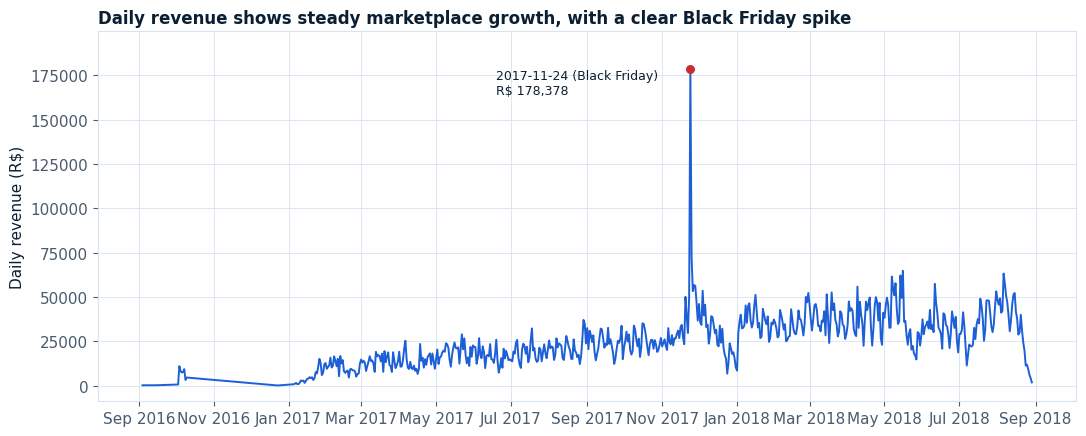

Peak day: 2017-11-24, revenue R$ 178,378 vs. 30-day median R$ 39,653


In [2]:
daily = df.groupby(df["order_purchase_timestamp"].dt.date)["revenue"].sum()
daily.index = pd.to_datetime(daily.index)

peak_date = daily.idxmax()

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(daily.index, daily.values, color=COLOR_ACCENT, linewidth=1.4)
ax.scatter([peak_date], [daily.max()], color=COLOR_DANGER, zorder=5, s=30)
ax.annotate(
    f"{peak_date.date()} (Black Friday)\nR$ {daily.max():,.0f}",
    xy=(peak_date, daily.max()),
    xytext=(-140, -18), textcoords="offset points",
    color=COLOR_TEXT_PRIMARY, fontsize=9,
)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_ylim(top=daily.max() * 1.12)
ax.set_ylabel("Daily revenue (R$)")
ax.set_title("Daily revenue shows steady marketplace growth, with a clear Black Friday spike", loc="left", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_daily_revenue_trend.png", dpi=150)
plt.show()

print(f"Peak day: {peak_date.date()}, revenue R$ {daily.max():,.0f} vs. 30-day median R$ {daily.rolling(30).median().iloc[-1]:,.0f}")

## 2. Weekly seasonality

Average revenue by day of week — online retail in this dataset skews toward the start of the work week and dips on weekends.

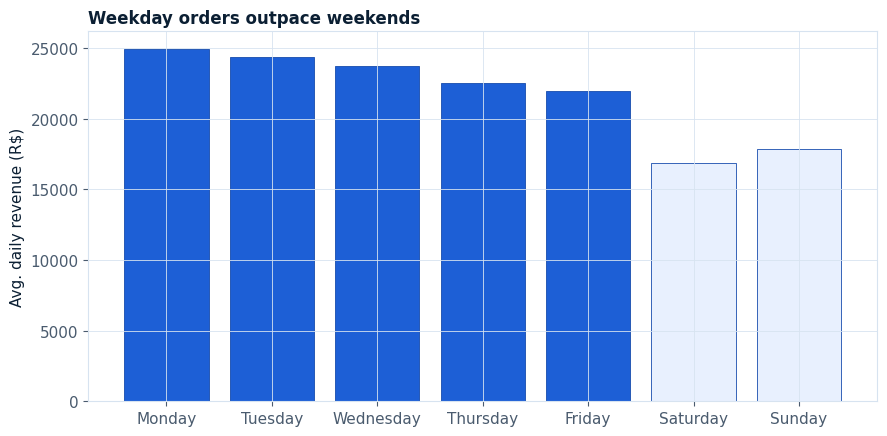

Weekday avg R$ 23,521/day vs weekend avg R$ 17,371/day (35% higher)


In [3]:
dow_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_dow = (
    df.groupby(df["order_purchase_timestamp"].dt.day_name())["revenue"].sum()
    .reindex(dow_order)
)
n_weeks = (df["order_purchase_timestamp"].max() - df["order_purchase_timestamp"].min()).days / 7
avg_by_dow = by_dow / n_weeks

colors = [COLOR_ACCENT if d not in ("Saturday", "Sunday") else COLOR_ACCENT_LIGHT for d in dow_order]

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(dow_order, avg_by_dow.values, color=colors, edgecolor=COLOR_ACCENT_HOVER, linewidth=0.6)
ax.set_ylabel("Avg. daily revenue (R$)")
ax.set_title("Weekday orders outpace weekends", loc="left", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_weekday_seasonality.png", dpi=150)
plt.show()

weekday_avg = avg_by_dow[["Monday","Tuesday","Wednesday","Thursday","Friday"]].mean()
weekend_avg = avg_by_dow[["Saturday","Sunday"]].mean()
print(f"Weekday avg R$ {weekday_avg:,.0f}/day vs weekend avg R$ {weekend_avg:,.0f}/day "
      f"({(weekday_avg/weekend_avg - 1)*100:.0f}% higher)")

## 3. Category mix

Top 10 product categories by revenue — a long tail with a handful of categories driving a large share of sales.

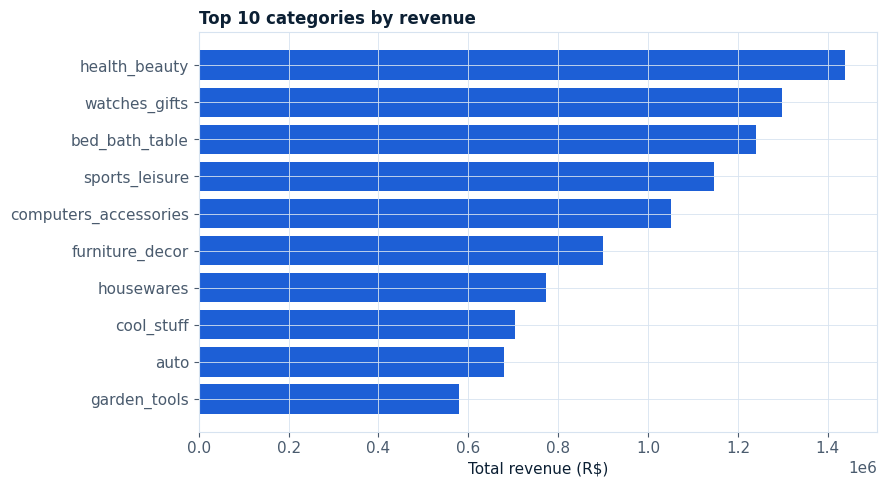

Top 10 categories account for 62% of total revenue


In [4]:
top_categories = (
    df.groupby("product_category_name_english")["revenue"].sum()
    .sort_values(ascending=False)
    .head(10)
)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top_categories.index[::-1], top_categories.values[::-1], color=COLOR_ACCENT)
ax.set_xlabel("Total revenue (R$)")
ax.set_title("Top 10 categories by revenue", loc="left", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "03_top_categories.png", dpi=150)
plt.show()

share = top_categories.sum() / df["revenue"].sum()
print(f"Top 10 categories account for {share*100:.0f}% of total revenue")

## 4. Geographic concentration

Customer state at checkout — Brazil's e-commerce demand is heavily concentrated in the Southeast, led by São Paulo.

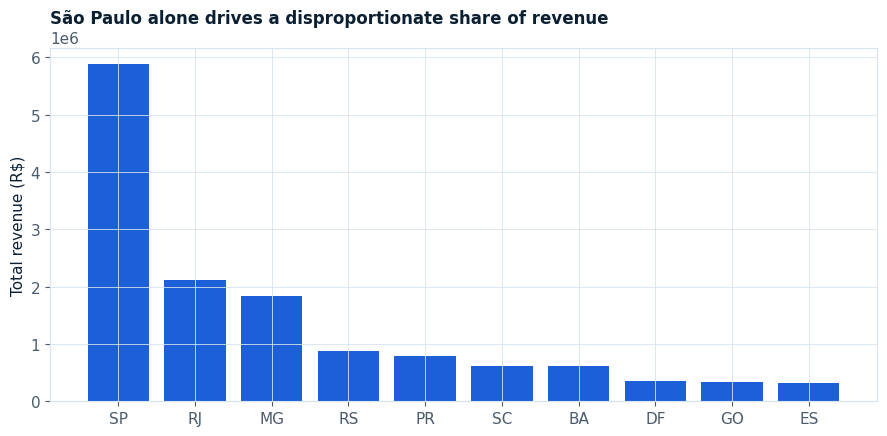

São Paulo (SP) alone accounts for 37% of total revenue


In [5]:
top_states = (
    df.groupby("customer_state")["revenue"].sum()
    .sort_values(ascending=False)
    .head(10)
)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(top_states.index, top_states.values, color=COLOR_ACCENT)
ax.set_ylabel("Total revenue (R$)")
ax.set_title("São Paulo alone drives a disproportionate share of revenue", loc="left", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "04_top_states.png", dpi=150)
plt.show()

sp_share = top_states["SP"] / df["revenue"].sum()
print(f"São Paulo (SP) alone accounts for {sp_share*100:.0f}% of total revenue")

## 5. Delivery time vs. customer satisfaction

Review score by delivery-time bucket — slower deliveries are visibly associated with lower review scores, a direct lever for the business.

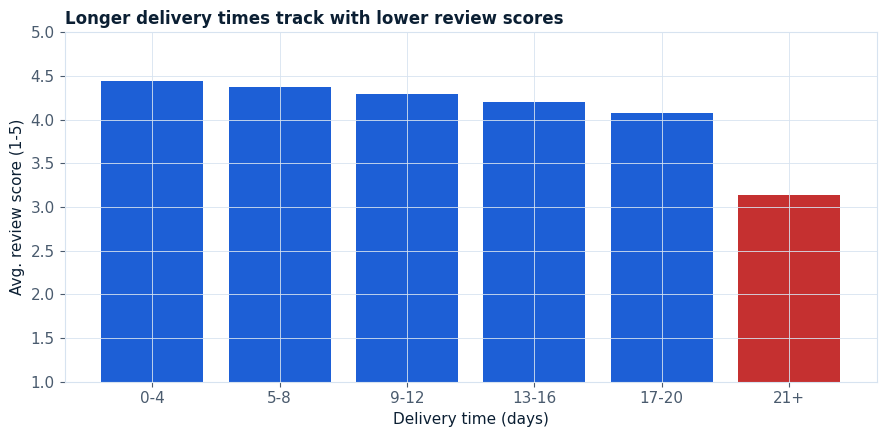

delivery_bucket
0-4      4.447510
5-8      4.375586
9-12     4.293185
13-16    4.205487
17-20    4.077470
21+      3.141125
Name: review_score, dtype: float64


In [6]:
reviewed = df.dropna(subset=["delivery_days", "review_score"]).drop_duplicates("order_id")
reviewed = reviewed[(reviewed["delivery_days"] >= 0) & (reviewed["delivery_days"] <= 60)]

bins = [0, 4, 8, 12, 16, 20, 60]
labels = ["0-4", "5-8", "9-12", "13-16", "17-20", "21+"]
reviewed["delivery_bucket"] = pd.cut(reviewed["delivery_days"], bins=bins, labels=labels, include_lowest=True)

avg_score = reviewed.groupby("delivery_bucket", observed=True)["review_score"].mean()

fig, ax = plt.subplots(figsize=(9, 4.5))
colors = [COLOR_ACCENT if s >= 4 else (COLOR_WARNING if s >= 3.5 else COLOR_DANGER) for s in avg_score.values]
ax.bar(avg_score.index.astype(str), avg_score.values, color=colors)
ax.set_ylim(1, 5)
ax.set_xlabel("Delivery time (days)")
ax.set_ylabel("Avg. review score (1-5)")
ax.set_title("Longer delivery times track with lower review scores", loc="left", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "05_delivery_vs_review.png", dpi=150)
plt.show()

print(avg_score)

## Key findings

1. **Growth + a real demand shock**: daily revenue trends upward through the dataset's window, with a sharp, unmistakable spike on Black Friday (Nov 24, 2017) — a genuine external shock similar in shape to a holiday effect, useful to flag as an outlier/regressor for forecasting rather than smoothing away.
2. **Weekday effect**: revenue is meaningfully higher on weekdays than weekends, a seasonality signal worth encoding as a day-of-week feature.
3. **Concentration risk**: the top 10 of ~70 categories account for the large majority of revenue, and São Paulo alone accounts for a disproportionate share of demand — both suggest a single national aggregate series is reasonable for a first forecasting pass, but a state- or category-level breakdown would likely forecast better long-term.
4. **Delivery time drives satisfaction**: average review score drops steadily as delivery time increases, a clear, actionable operational insight independent of the forecasting task.